In [28]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import gamma
from scipy.signal import butter, filtfilt


In [24]:

# Set random seed for reproducibility
np.random.seed(42)

# Parameters
n_groups = 9
n_infants = 15
n_channels = 10
sampling_rate = 10  
duration_secs = 19  
n_timepoints = duration_secs * sampling_rate
stim_onset = 0
stim_duration = 9
time = np.linspace(0, duration_secs, n_timepoints)

# Canonical HRF function (difference of two gamma functions)
def canonical_hrf(t, onset, duration, peak_delay=6, under_delay=16, p_u_ratio=6, amp=1):
    t_sec = t - onset  # align time with stimulus
    t_sec[t_sec < 0] = 0  # no response before onset

    # gamma.pdf can simulate the hemodynamic bump
    hrf_peak = gamma.pdf(t_sec, peak_delay)  # peak around 6s
    hrf_undershoot = gamma.pdf(t_sec, under_delay) / p_u_ratio  # slower undershoot
    hrf = hrf_peak - hrf_undershoot

    # Normalize and apply amplitude
    hrf = amp * hrf / np.max(np.abs(hrf))
    return hrf

# Habituation profiles
def linear_habituation(trial, max_trials=15):
    return 1 - trial / max_trials

def exponential_habituation(trial, tau=5):
    return np.exp(-trial / tau)

def no_habituation(trial):
    return 1

# Noise profiles
def get_noise(profile, size):
    if profile == 'clean':
        return np.random.normal(0, 0.02, size)
    elif profile == 'average':
        return np.random.normal(0, 0.1, size)
    elif profile == 'noisy':
        return np.random.normal(0, 0.3, size)

# Distance-based decay of activation (from channel 0)
channel_distances = np.arange(n_channels)

# Container for all data
simulated_data = []

# Iterate over all 3x3 condition combinations
habituation_profiles = ['linear', 'exponential', 'none']
noise_profiles = ['clean', 'average', 'noisy']

for hab in habituation_profiles:
    for noise in noise_profiles:
        group_label = f"{hab}_{noise}"
        for infant_id in range(n_infants):
            
            # Random peak delay per infant
            base_peak_delay = np.random.uniform(9, 13)

            for ch in range(n_channels):
                for chrom in ['HbO', 'HbR']:
                    trial_curve = np.zeros(n_timepoints)

                    for trial in range(15):

                        # Slight variability in peak delay per trial (~±0.5s)
                        peak_delay_trial = base_peak_delay + np.random.uniform(-0.5, 0.5)

                        # Habituation scaling
                        if hab == 'linear':
                            hab_factor = linear_habituation(trial)
                        elif hab == 'exponential':
                            hab_factor = exponential_habituation(trial)
                        else:
                            hab_factor = no_habituation(trial)
                        
                        # Distance decay
                        amp = 1 / (1 + channel_distances[ch])
                        amp *= hab_factor

                        # Opposite polarity for HbR
                        sign = 1 if chrom == 'HbO' else -0.6
                        signal = canonical_hrf(time, stim_onset, stim_duration, peak_delay=peak_delay_trial, amp=amp * sign)

                        # Add noise
                        noise_array = get_noise(noise, n_timepoints)

                        # Add to trial
                        trial_curve += signal + noise_array
                    
                    trial_curve /= 15
                    simulated_data.append({
                        'Group': group_label,
                        'Infant': infant_id,
                        'Channel': ch,
                        'Chromophore': chrom,
                        'Signal': trial_curve
                    })


df_simulated = pd.DataFrame(simulated_data)

df_simulated


,Group,Infant,Channel,Chromophore,Signal
0,linear_clean,0,0,HbO,"[0.0006830225167051396, 0.0046286141507133356,..."
1,linear_clean,0,0,HbR,"[-0.000630404294902435, 0.000738253645177149, ..."
2,linear_clean,0,1,HbO,"[0.0005353115247070395, 0.003280493454845919, ..."
3,linear_clean,0,1,HbR,"[0.0023765486086099815, 0.0007140726837933134,..."
4,linear_clean,0,2,HbO,"[0.000912920981488981, -0.0035426449522377476,..."
...,...,...,...,...,...
2695,none_noisy,14,7,HbR,"[-0.031209007975248806, -0.06644734364882242, ..."
2696,none_noisy,14,8,HbO,"[-0.05922188860221562, 0.14164881571767757, -0..."
2697,none_noisy,14,8,HbR,"[0.010790241735618189, -0.052576638146213606, ..."
2698,none_noisy,14,9,HbO,"[-0.01619731568508561, 0.08821000736014546, -0..."


In [29]:
# Set random seed for reproducibility
np.random.seed(42)
# Parameters
n_groups = 9
n_infants = 15
n_channels = 10
sampling_rate = 10
duration_secs = 19
n_timepoints = duration_secs * sampling_rate
stim_onset = 0
stim_duration = 9
time = np.linspace(0, duration_secs, n_timepoints)
# Canonical HRF function (difference of two gamma functions)
def canonical_hrf(t, onset, duration, peak_delay=6, under_delay=16, p_u_ratio=6, amp=1):
    t_sec = t - onset # align time with stimulus
    t_sec[t_sec < 0] = 0 # no response before onset
    # gamma.pdf can simulate the hemodynamic bump
    hrf_peak = gamma.pdf(t_sec, peak_delay) # peak around 6s
    hrf_undershoot = gamma.pdf(t_sec, under_delay) / p_u_ratio # slower undershoot
    hrf = hrf_peak - hrf_undershoot
    # Normalize and apply amplitude
    hrf = amp * hrf / np.max(np.abs(hrf))
    return hrf

# Habituation profiles
def linear_habituation(trial, max_trials=15):
    return 1 - trial / max_trials

def exponential_habituation(trial, tau=5):
    return np.exp(-trial / tau)

def no_habituation(trial):
    return 1

# Improved noise profiles with slower oscillations
def get_noise(profile, size):
    # First generate white noise
    white_noise = np.random.normal(0, 1, size)
    
    # Create a low-pass filter to slow down oscillations
    # Lower cutoff = slower oscillations
    if profile == 'clean':
        # Minimal slow oscillations
        cutoff = 0.1  # Hz
        filtered_noise = low_pass_filter(white_noise, cutoff, sampling_rate)
        return filtered_noise * 0.02  # Scale amplitude
    elif profile == 'average':
        # Moderate slow oscillations
        cutoff = 0.2  # Hz
        filtered_noise = low_pass_filter(white_noise, cutoff, sampling_rate)
        return filtered_noise * 0.1  # Scale amplitude
    elif profile == 'noisy':
        # Strong slow oscillations
        cutoff = 0.3  # Hz
        filtered_noise = low_pass_filter(white_noise, cutoff, sampling_rate)
        return filtered_noise * 0.3  # Scale amplitude

# Simple low-pass filter implementation
def low_pass_filter(signal, cutoff, fs):
    # Create a Butterworth low-pass filter
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    # Use a lower order for smoother, slower oscillations
    b, a = butter(2, normal_cutoff, btype='low', analog=False)
    # Apply the filter
    filtered_signal = filtfilt(b, a, signal)
    return filtered_signal

# Distance-based decay of activation (from channel 0)
channel_distances = np.arange(n_channels)
# Container for all data
simulated_data = []
# Iterate over all 3x3 condition combinations
habituation_profiles = ['linear', 'exponential', 'none']
noise_profiles = ['clean', 'average', 'noisy']
for hab in habituation_profiles:
    for noise in noise_profiles:
        group_label = f"{hab}_{noise}"
        for infant_id in range(n_infants):
            # Random peak delay per infant
            base_peak_delay = np.random.uniform(9, 13)
            for ch in range(n_channels):
                for chrom in ['HbO', 'HbR']:
                    trial_curve = np.zeros(n_timepoints)
                    for trial in range(15):
                        # Slight variability in peak delay per trial (~±0.5s)
                        peak_delay_trial = base_peak_delay + np.random.uniform(-0.5, 0.5)
                        # Habituation scaling
                        if hab == 'linear':
                            hab_factor = linear_habituation(trial)
                        elif hab == 'exponential':
                            hab_factor = exponential_habituation(trial)
                        else:
                            hab_factor = no_habituation(trial)
                        # Distance decay
                        amp = 1 / (1 + channel_distances[ch])
                        amp *= hab_factor
                        # Opposite polarity for HbR
                        sign = 1 if chrom == 'HbO' else -0.6
                        signal = canonical_hrf(time, stim_onset, stim_duration, peak_delay=peak_delay_trial, amp=amp * sign)
                        # Add noise
                        noise_array = get_noise(noise, n_timepoints)
                        # Add to trial
                        trial_curve += signal + noise_array
                    trial_curve /= 15
                    simulated_data.append({
                        'Group': group_label,
                        'Infant': infant_id,
                        'Channel': ch,
                        'Chromophore': chrom,
                        'Signal': trial_curve
                     })
df_simulated = pd.DataFrame(simulated_data)
df_simulated

,Group,Infant,Channel,Chromophore,Signal
0,linear_clean,0,0,HbO,"[0.001110394564658182, 0.001087725025455001, 0..."
1,linear_clean,0,0,HbR,"[0.002336280529638061, 0.0021467089108935856, ..."
2,linear_clean,0,1,HbO,"[-0.0008835829477944543, -0.000842370755527685..."
3,linear_clean,0,1,HbR,"[0.0011964672193088466, 0.001064842162004782, ..."
4,linear_clean,0,2,HbO,"[0.0011089038649082688, 0.001108148588051907, ..."
...,...,...,...,...,...
2695,none_noisy,14,7,HbR,"[-0.02909831982388368, -0.02554077911549418, -..."
2696,none_noisy,14,8,HbO,"[-0.05402160118497614, -0.047498174140384083, ..."
2697,none_noisy,14,8,HbR,"[0.018357048434116466, 0.013212498239311869, 0..."
2698,none_noisy,14,9,HbO,"[-0.009624712218610372, -0.009513669349037135,..."


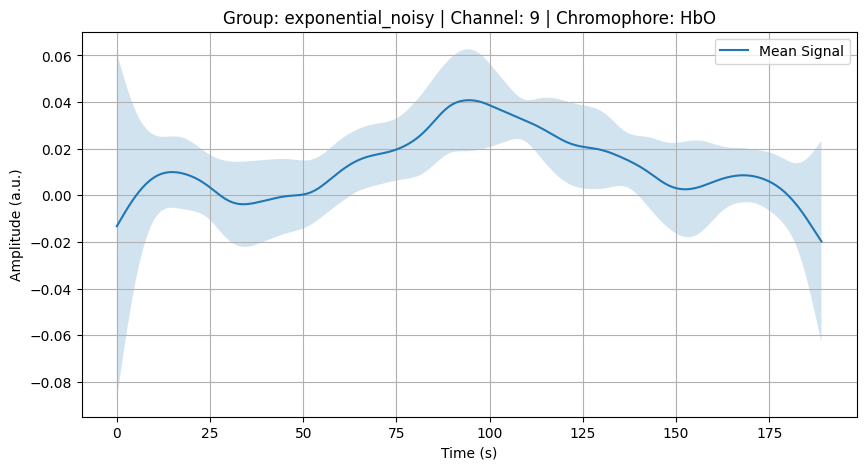

In [34]:
def plot_average_response(df, group, channel, chromophore):
    subset = df[
        (df['Group'] == group) &
        (df['Channel'] == channel) &
        (df['Chromophore'] == chromophore)
    ]
    
    signals = np.stack(subset['Signal'].values)
    mean_signal = np.mean(signals, axis=0)
    std_signal = np.std(signals, axis=0)

    plt.figure(figsize=(10, 5))
    plt.plot(mean_signal, label='Mean Signal')
    plt.fill_between(np.arange(len(mean_signal)), mean_signal - std_signal, mean_signal + std_signal, alpha=0.2)
    plt.title(f"Group: {group} | Channel: {channel} | Chromophore: {chromophore}")
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude (a.u.)")
    plt.legend()
    plt.grid(True)
    plt.show()

# Example usage:
plot_average_response(df_simulated, group='exponential_noisy', channel=9, chromophore='HbO')
